# Project context
This project was completed as a group assignment for the Privacy Preserving Information Access course.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime as dt, UTC
import csv
import kagglehub
import re
from collections import defaultdict


c:\Dev\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Data pre-processing

In [2]:
# Download latest version
nf_base_path = kagglehub.dataset_download("netflix-inc/netflix-prize-data")
print("Path to dataset files:", nf_base_path)

# Download latest version
ml_base_path = kagglehub.dataset_download("grouplens/movielens-20m-dataset")
print("Path to dataset files:", ml_base_path)

100%|██████████| 683M/683M [00:21<00:00, 34.0MB/s] 

Extracting files...


Path to dataset files: C:\Users\aless\.cache\kagglehub\datasets\netflix-inc\netflix-prize-data\versions\2


100%|██████████| 195M/195M [00:07<00:00, 28.3MB/s] 

Extracting files...


Path to dataset files: C:\Users\aless\.cache\kagglehub\datasets\grouplens\movielens-20m-dataset\versions\1


In [3]:
# Netflix data pre-processing
NF_TITLES_PATH = f"{nf_base_path}/movie_titles.csv"
NF_TRAINING_DIR = f"{nf_base_path}/combined_data"

data = []
with open(NF_TITLES_PATH, encoding="ISO-8859-1") as nf:
    for movie_id, year, *title in csv.reader(nf):
        mv_title = (''.join(title) + "(" + year + ")" ).lower().replace(" ", "")
        mv_title = mv_title.replace('"', "")
        data.append({'movie_id': int(movie_id), 'title': mv_title})
netflix_movies = pd.DataFrame(data, columns=['movie_id', 'title'])
del data
display(netflix_movies.head())

,movie_id,title
0,1,dinosaurplanet(2003)
1,2,isleofmantt2004review(2004)
2,3,character(1997)
3,4,paulaabdul'sgetup&dance(1994)
4,5,theriseandfallofecw(2004)


In [4]:
def read_movies_txt(file_path):
    result = []
    with open(file_path, 'r') as file:
        for line in file:
            line = line.strip()
            if not line:
                continue
            if line.endswith(':'):
                movie_id = int(line[:-1])
            else:
                user_id, rating, timestamp = line.split(',')
                date_obj = dt.strptime(timestamp, "%Y-%m-%d")
                timestamp = int(date_obj.timestamp())
                result.append({
                    'movie_id': movie_id,
                    'user_id': user_id,
                    'rating': rating,
                    'timestamp': timestamp
                })
    return pd.DataFrame(result)

In [5]:
tmp_1 = read_movies_txt(f"{NF_TRAINING_DIR}_1.txt")

tmp_2 = read_movies_txt(f"{NF_TRAINING_DIR}_2.txt")
df_nf_ratings_tmp = pd.concat([tmp_1, tmp_2], axis=0, ignore_index=True)
del tmp_1, tmp_2

tmp_3 = read_movies_txt(f"{NF_TRAINING_DIR}_3.txt")
df_nf_ratings_tmp = pd.concat([df_nf_ratings_tmp, tmp_3], axis=0, ignore_index=True)
del tmp_3

tmp_4 = read_movies_txt(f"{NF_TRAINING_DIR}_4.txt")
df_nf_ratings_tmp = pd.concat([df_nf_ratings_tmp, tmp_4], axis=0, ignore_index=True)
del tmp_4
display(df_nf_ratings_tmp.head())

,movie_id,user_id,rating,timestamp
0,1,1488844,3,1125957600
1,1,822109,5,1115935200
2,1,885013,4,1129672800
3,1,30878,4,1135551600
4,1,823519,3,1083535200


In [7]:
df_nf_ratings = pd.merge(
    df_nf_ratings_tmp,
    netflix_movies,
    on='movie_id',
    how='inner'
)
df_nf_ratings = df_nf_ratings.drop('movie_id', axis=1)
display(df_nf_ratings.head())
df_nf_ratings.to_csv('df_nf_ratings.csv', index=False)

,user_id,rating,timestamp,title
0,1488844,3,1125957600,dinosaurplanet(2003)
1,822109,5,1115935200,dinosaurplanet(2003)
2,885013,4,1129672800,dinosaurplanet(2003)
3,30878,4,1135551600,dinosaurplanet(2003)
4,823519,3,1083535200,dinosaurplanet(2003)


In [8]:
del df_nf_ratings_tmp, netflix_movies

In [9]:
# Define mix and max timestamp
min_timestamp = df_nf_ratings['timestamp'].min()
max_timestamp = df_nf_ratings['timestamp'].max()

print(f"Range {dt.fromtimestamp(min_timestamp, UTC).strftime('%Y-%m-%d')} - {dt.fromtimestamp(max_timestamp, UTC).strftime('%Y-%m-%d')}")

Range 1999-11-10 - 2005-12-30


In [10]:
# MovieLens data pre-processing
ML_RATINGS_PATH = f"{ml_base_path}/rating.csv"
ML_MOVIES_PATH = f"{ml_base_path}/movie.csv"

df_ml_ratings_tmp = pd.read_csv(
    ML_RATINGS_PATH,
    skiprows=1,
    encoding="UTF-8",
    names=["user_id", "movie_id", "rating", "timestamp"]
)
df_ml_ratings_tmp['timestamp'] = pd.to_datetime(df_ml_ratings_tmp['timestamp'])
df_ml_ratings_tmp['timestamp'] = df_ml_ratings_tmp['timestamp'].astype('int64') // 10**9
print(df_ml_ratings_tmp.head())



   user_id  movie_id  rating   timestamp
0        1         2     3.5  1112486027
1        1        29     3.5  1112484676
2        1        32     3.5  1112484819
3        1        47     3.5  1112484727
4        1        50     3.5  1112484580


In [11]:
# Remove out of bounds reviews
print(len(df_ml_ratings_tmp))
df_ml_ratings_tmp = df_ml_ratings_tmp[(df_ml_ratings_tmp["timestamp"] >= min_timestamp) & (df_ml_ratings_tmp["timestamp"] <= max_timestamp)]
list_ml_movies = df_ml_ratings_tmp.movie_id.unique()
print(len(df_ml_ratings_tmp))

20000263
8617379


In [12]:
data = []
with open(ML_MOVIES_PATH, encoding="UTF-8") as ml:
    reader = csv.reader(ml)
    next(reader)
    for movie_id, title, genres in reader:
        movie_id = movie_id
        if int(movie_id) in list_ml_movies:
            mv_title = title.lower().replace(" ", "")
            mv_title = mv_title.replace('"', '')
            data.append({'movie_id': int(movie_id), 'title': mv_title})
movielens_movies = pd.DataFrame(data, columns=['movie_id', 'title'])
del data
display(movielens_movies.head())

,movie_id,title
0,1,toystory(1995)
1,2,jumanji(1995)
2,3,grumpieroldmen(1995)
3,4,waitingtoexhale(1995)
4,5,fatherofthebridepartii(1995)


In [ ]:
df_ml_ratings = pd.merge(
    df_ml_ratings_tmp,
    movielens_movies,
    on='movie_id',
    how='inner'
)
df_ml_ratings = df_ml_ratings.drop('movie_id', axis=1)
del df_ml_ratings_tmp, movielens_movies
df_ml_ratings["rating"] = np.round(df_ml_ratings["rating"])
display(df_ml_ratings.head())
df_ml_ratings.to_csv('df_ml_ratings.csv', index=False)

# Scoring Function

In [83]:
def compute_score(df_ml_ratings, df_nf_ratings, weight_map, r0=1.5, d0=30, com_movies=None):
    if com_movies is None:
        com_movies = df_nf_ratings['title'].unique().intersection(df_ml_ratings['title'].unique())
    
    df_ml_ratings = df_ml_ratings.loc[com_movies, :]
    df_nf_ratings = df_nf_ratings.loc[com_movies, :]
        
    # Calculate absolute differences
    res = np.abs(df_nf_ratings.subtract(df_ml_ratings, fill_value=0).astype(np.int64))
    
    # Scoring Algorithm
    res.loc[:,"score"] = weight_map.loc[com_movies] * (np.exp(-res.loc[:,'rating']/r0) + np.exp(-res.loc[:,'timestamp']/(d0*86400)))
    
    res.drop(["rating", "timestamp"], axis=1, inplace=True)
    res.set_index(['user_id_nf', 'user_id_ml'], inplace=True)
    
    # Group by pairs of users and sum scores
    R = res.groupby(level=[0, 1]).sum()
    return R

def calculate_eccentricity(R_group):
    # R_group is a Series of scores for one Netflix user against multiple ML users
    tempScore = np.array(R_group)
    if len(tempScore) < 2: return 0
    
    stdev = np.std(tempScore)
    if stdev == 0: return 0
    
    best1 = np.max(tempScore)
    idx1 = np.argmax(tempScore)
    tempScore = np.delete(tempScore, idx1)
    best2 = np.max(tempScore)
    
    return (best1 - best2) / stdev

# Execution

## Scoring Subsets

In [3]:
# Re-load or use existing
df_ml_ratings = pd.read_csv("df_ml_ratings.csv")
df_nf_ratings = pd.read_csv("df_nf_ratings.csv")

#dff = netflix
#dbb = movielens
display(df_ml_ratings.head())
display(df_nf_ratings.head())

all_ml_users = df_ml_ratings["user_id"].unique()
print(f"We have {len(all_ml_users)} users in MovieLens")

all_nf_users = df_nf_ratings["user_id"].unique()
print(f"We have {len(all_nf_users)} users in Netflix")

,user_id,rating,timestamp,title
0,1,4.0,1112486027,jumanji(1995)
1,1,4.0,1112484676,"cityoflostchildren,the(citédesenfantsperdus,la..."
2,1,4.0,1112484819,twelvemonkeys(a.k.a.12monkeys)(1995)
3,1,4.0,1112484727,seven(a.k.a.se7en)(1995)
4,1,4.0,1112484580,"usualsuspects,the(1995)"


,user_id,rating,timestamp,title
0,1488844,3,1125957600,dinosaurplanet(2003)
1,822109,5,1115935200,dinosaurplanet(2003)
2,885013,4,1129672800,dinosaurplanet(2003)
3,30878,4,1135551600,dinosaurplanet(2003)
4,823519,3,1083535200,dinosaurplanet(2003)


We have 49205 users in MovieLens
We have 480189 users in Netflix


In [4]:
weight = 1 / np.log10(df_nf_ratings.loc[:, "title"].value_counts())

In [18]:
ml_batch_size = 5000
nf_batch_size = 1000 
matched_users = {}

ml_subset = df_ml_ratings.loc[(df_ml_ratings["user_id"] < ml_batch_size)].copy()
ml_subset.rename(columns={"user_id": "user_id_ml"}, inplace=True)
ml_subset.set_index(["title"], inplace=True)
print(f"Considering {len(ml_subset)} records for MovieLens")
    
for i in range(0, len(all_nf_users), nf_batch_size):
    current_users = all_nf_users[i : i + nf_batch_size]
    print(f"Analyzing Netflix users {i} - {i + nf_batch_size}")

    nf_batch = df_nf_ratings[df_nf_ratings["user_id"].isin(current_users)].copy()
    nf_batch.rename(columns={"user_id": "user_id_nf"}, inplace=True)
    nf_batch.set_index(["title"], inplace=True)
    
    com_movies = nf_batch.index.intersection(ml_subset.index).unique()

    R = compute_score(ml_subset, nf_batch, weight, com_movies=com_movies, d0=30)
    
    # Eccentricità e Matching
    nf_users_in_batch = R.index.levels[0]
    for netflix_user_id in nf_users_in_batch:
        if netflix_user_id in R.index:
            user_scores = R.loc[netflix_user_id]
            scores_series = user_scores["score"]
            
            ecc = calculate_eccentricity(scores_series)
            if ecc >= 1.5:
                best_ml_idx = scores_series.argmax()
                matched_users[(netflix_user_id, scores_series.index[best_ml_idx])] = ecc
                
result_serializable = {
    f"({int(k[0])}, {int(k[1])})": float(v)
    for k, v in matched_users.items()
}
with open('results/risultato_30gg.txt', 'w') as f:
    for key, value in result_serializable.items():
        f.write(f"{key}: {value}\n")
                    
print(f"Processo completato. Trovati {len(matched_users)} match su tutto il dataset.")

Considering 319426 records for MovieLens
Analyzing Netflix users 0 - 1000
Analyzing Netflix users 1000 - 2000
Analyzing Netflix users 2000 - 3000
Analyzing Netflix users 3000 - 4000
Analyzing Netflix users 4000 - 5000
Analyzing Netflix users 5000 - 6000
Analyzing Netflix users 6000 - 7000
Analyzing Netflix users 7000 - 8000
Analyzing Netflix users 8000 - 9000
Analyzing Netflix users 9000 - 10000
Analyzing Netflix users 10000 - 11000
Analyzing Netflix users 11000 - 12000
Analyzing Netflix users 12000 - 13000
Analyzing Netflix users 13000 - 14000
Analyzing Netflix users 14000 - 15000
Analyzing Netflix users 15000 - 16000
Analyzing Netflix users 16000 - 17000
Analyzing Netflix users 17000 - 18000
Analyzing Netflix users 18000 - 19000
Analyzing Netflix users 19000 - 20000
Analyzing Netflix users 20000 - 21000
Analyzing Netflix users 21000 - 22000
Analyzing Netflix users 22000 - 23000
Analyzing Netflix users 23000 - 24000
Analyzing Netflix users 24000 - 25000
Analyzing Netflix users 25000 -

In [5]:
ml_batch_size = 5000
nf_batch_size = 1000 
matched_users = {}

ml_subset = df_ml_ratings.loc[(df_ml_ratings["user_id"] < ml_batch_size)].copy()
ml_subset.rename(columns={"user_id": "user_id_ml"}, inplace=True)
ml_subset.set_index(["title"], inplace=True)
print(f"Considering {len(ml_subset)} records for MovieLens")
    
for i in range(0, len(all_nf_users), nf_batch_size):
    current_users = all_nf_users[i : i + nf_batch_size]
    print(f"Analyzing Netflix users {i} - {i + nf_batch_size}")

    nf_batch = df_nf_ratings[df_nf_ratings["user_id"].isin(current_users)].copy()
    nf_batch.rename(columns={"user_id": "user_id_nf"}, inplace=True)
    nf_batch.set_index(["title"], inplace=True)
    
    com_movies = nf_batch.index.intersection(ml_subset.index).unique()

    R = compute_score(ml_subset, nf_batch, weight, com_movies=com_movies, d0=1)
    
    # Eccentricità e Matching
    nf_users_in_batch = R.index.levels[0]
    for netflix_user_id in nf_users_in_batch:
        if netflix_user_id in R.index:
            user_scores = R.loc[netflix_user_id]
            scores_series = user_scores["score"]
            
            ecc = calculate_eccentricity(scores_series)
            if ecc >= 1.5:
                best_ml_idx = scores_series.argmax()
                matched_users[(netflix_user_id, scores_series.index[best_ml_idx])] = ecc
                
result_serializable = {
    f"({int(k[0])}, {int(k[1])})": float(v)
    for k, v in matched_users.items()
}
with open('results/risultato_1gg.txt', 'w') as f:
    for key, value in result_serializable.items():
        f.write(f"{key}: {value}\n")
                    
print(f"Processo completato. Trovati {len(matched_users)} match su tutto il dataset.")

Considering 319426 records for MovieLens
Analyzing Netflix users 0 - 1000
Analyzing Netflix users 1000 - 2000
Analyzing Netflix users 2000 - 3000
Analyzing Netflix users 3000 - 4000
Analyzing Netflix users 4000 - 5000
Analyzing Netflix users 5000 - 6000
Analyzing Netflix users 6000 - 7000
Analyzing Netflix users 7000 - 8000
Analyzing Netflix users 8000 - 9000
Analyzing Netflix users 9000 - 10000
Analyzing Netflix users 10000 - 11000
Analyzing Netflix users 11000 - 12000
Analyzing Netflix users 12000 - 13000
Analyzing Netflix users 13000 - 14000
Analyzing Netflix users 14000 - 15000
Analyzing Netflix users 15000 - 16000
Analyzing Netflix users 16000 - 17000
Analyzing Netflix users 17000 - 18000
Analyzing Netflix users 18000 - 19000
Analyzing Netflix users 19000 - 20000
Analyzing Netflix users 20000 - 21000
Analyzing Netflix users 21000 - 22000
Analyzing Netflix users 22000 - 23000
Analyzing Netflix users 23000 - 24000
Analyzing Netflix users 24000 - 25000
Analyzing Netflix users 25000 -

In [6]:
ml_batch_size = 5000
nf_batch_size = 1000 
matched_users = {}

ml_subset = df_ml_ratings.loc[(df_ml_ratings["user_id"] < ml_batch_size)].copy()
ml_subset.rename(columns={"user_id": "user_id_ml"}, inplace=True)
ml_subset.set_index(["title"], inplace=True)
print(f"Considering {len(ml_subset)} records for MovieLens")
    
for i in range(0, len(all_nf_users), nf_batch_size):
    current_users = all_nf_users[i : i + nf_batch_size]
    print(f"Analyzing Netflix users {i} - {i + nf_batch_size}")

    nf_batch = df_nf_ratings[df_nf_ratings["user_id"].isin(current_users)].copy()
    nf_batch.rename(columns={"user_id": "user_id_nf"}, inplace=True)
    nf_batch.set_index(["title"], inplace=True)
    
    com_movies = nf_batch.index.intersection(ml_subset.index).unique()

    R = compute_score(ml_subset, nf_batch, weight, com_movies=com_movies, d0=7)
    
    # Eccentricità e Matching
    nf_users_in_batch = R.index.levels[0]
    for netflix_user_id in nf_users_in_batch:
        if netflix_user_id in R.index:
            user_scores = R.loc[netflix_user_id]
            scores_series = user_scores["score"]
            
            ecc = calculate_eccentricity(scores_series)
            if ecc >= 1.5:
                best_ml_idx = scores_series.argmax()
                matched_users[(netflix_user_id, scores_series.index[best_ml_idx])] = ecc
                
result_serializable = {
    f"({int(k[0])}, {int(k[1])})": float(v)
    for k, v in matched_users.items()
}
with open('results/risultato_7gg.txt', 'w') as f:
    for key, value in result_serializable.items():
        f.write(f"{key}: {value}\n")
                    
print(f"Processo completato. Trovati {len(matched_users)} match su tutto il dataset.")

Considering 319426 records for MovieLens
Analyzing Netflix users 0 - 1000
Analyzing Netflix users 1000 - 2000
Analyzing Netflix users 2000 - 3000
Analyzing Netflix users 3000 - 4000
Analyzing Netflix users 4000 - 5000
Analyzing Netflix users 5000 - 6000
Analyzing Netflix users 6000 - 7000
Analyzing Netflix users 7000 - 8000
Analyzing Netflix users 8000 - 9000
Analyzing Netflix users 9000 - 10000
Analyzing Netflix users 10000 - 11000
Analyzing Netflix users 11000 - 12000
Analyzing Netflix users 12000 - 13000
Analyzing Netflix users 13000 - 14000
Analyzing Netflix users 14000 - 15000
Analyzing Netflix users 15000 - 16000
Analyzing Netflix users 16000 - 17000
Analyzing Netflix users 17000 - 18000
Analyzing Netflix users 18000 - 19000
Analyzing Netflix users 19000 - 20000
Analyzing Netflix users 20000 - 21000
Analyzing Netflix users 21000 - 22000
Analyzing Netflix users 22000 - 23000
Analyzing Netflix users 23000 - 24000
Analyzing Netflix users 24000 - 25000
Analyzing Netflix users 25000 -

In [7]:
def rounding(valore):
    return np.round(valore * 2) / 2

def plot_match_counts(filename, title):
    pattern = r"\((\d+),\s*(\d+)\):\s*([\d\.]+)"

    data = []
    with open(filename, "r") as file:
            for linea in file:
                linea = linea.strip()
                if linea:  
                    match = re.match(pattern, linea)
                    if match:
                        netflix_id = int(match.group(1))
                        movielens_id = int(match.group(2))
                        eccentricity = float(match.group(3))
                        eccentricity_rounded = rounding(eccentricity)
                        data.append([netflix_id, movielens_id, round(eccentricity_rounded, 1)])

    df = pd.DataFrame(data, columns=["netflix_id", "movielens_id", "eccentricity"])


    eccentricity_counts = df["eccentricity"].value_counts().sort_index()

    # Creazione del grafico
    plt.figure(figsize=(10, 6))
    plt.bar(eccentricity_counts.index, eccentricity_counts.values, color='skyblue')
    max_etichette_x = 10  
    step_x = max(1, len(eccentricity_counts) // max_etichette_x)
    etichette_x_selezionate = eccentricity_counts.index[::step_x]
    plt.xticks(etichette_x_selezionate, rotation=45, ha='right')  
    plt.xlabel("Eccentricity")
    plt.ylabel("Number of matches")
    plt.title(title)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()


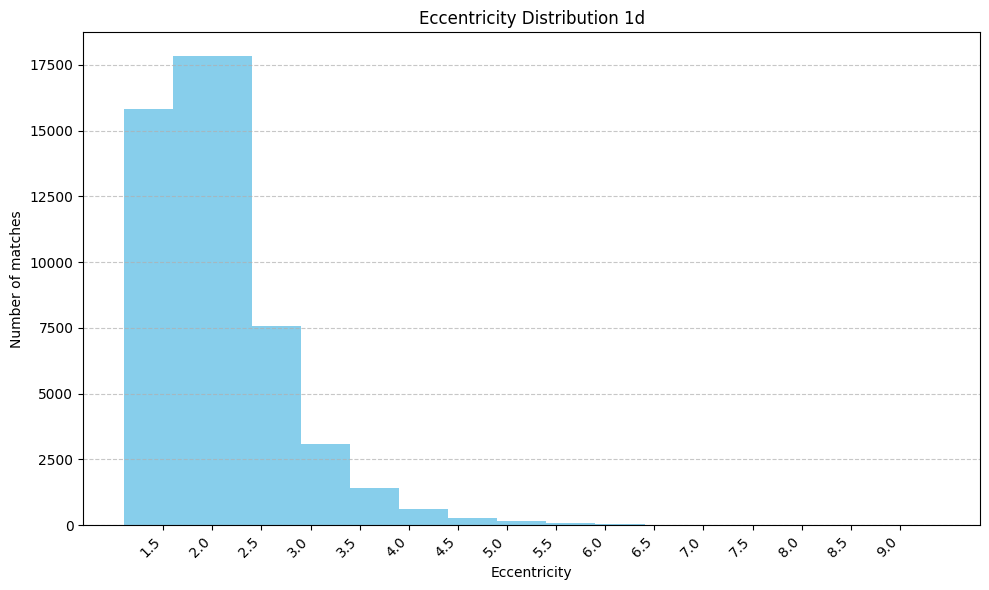

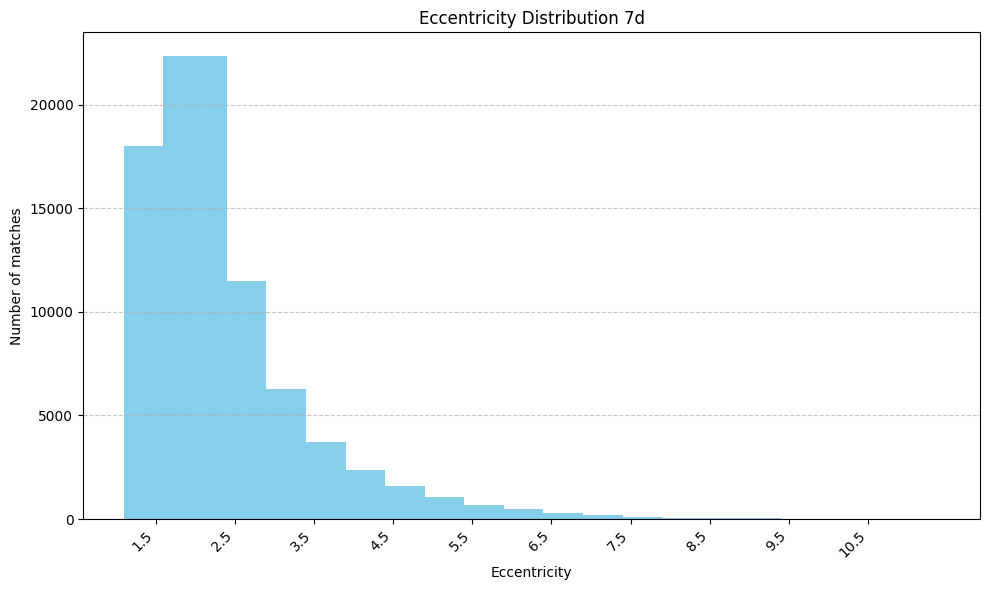

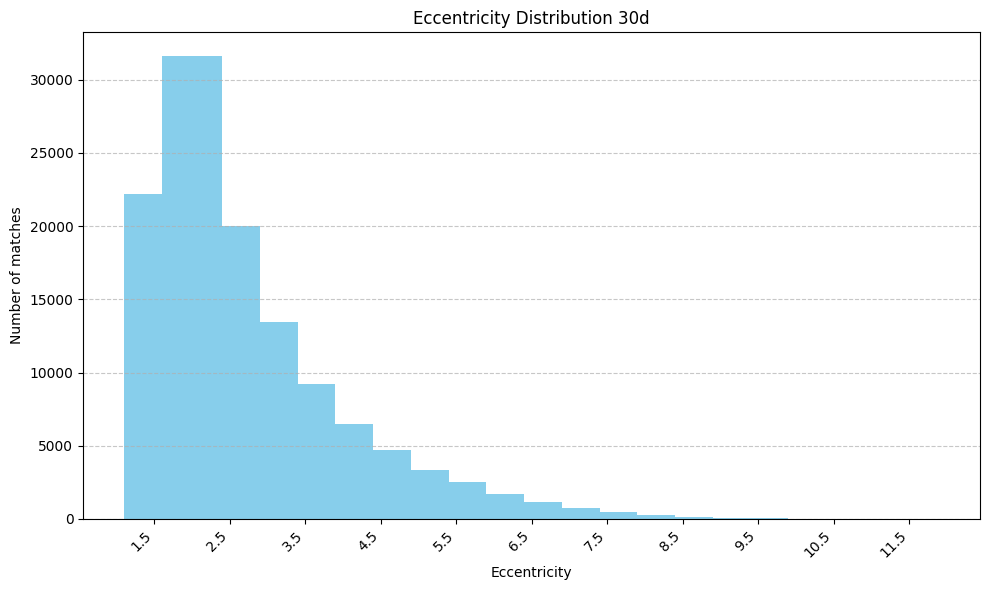

In [10]:
plot_match_counts('results/risultato_1gg.txt', 'Eccentricity Distribution 1d')
plot_match_counts('results/risultato_7gg.txt', 'Eccentricity Distribution 7d')
plot_match_counts('results/risultato_30gg.txt', 'Eccentricity Distribution 30d')

In [11]:
def find_max_eccentricity(filename, time_period):
    pattern = r"\((\d+),\s*(\d+)\):\s*([\d\.]+)"
    data = []
    with open(filename, "r") as file:
        for linea in file:
            linea = linea.strip()
            if linea:  
                match = re.match(pattern, linea)
                if match:
                    netflix_id = int(match.group(1))
                    movielens_id = int(match.group(2))
                    eccentricity = float(match.group(3))
                    eccentricity_rounded = rounding(eccentricity)
                    data.append([netflix_id, movielens_id, round(eccentricity_rounded, 1)])

    df = pd.DataFrame(data, columns=["netflix_id", "movielens_id", "eccentricity"])
    max_eccentricity_value = df["eccentricity"].max()
    print(f"Max value eccentricity for {time_period}d: {max_eccentricity_value}")

In [13]:
find_max_eccentricity('results/risultato_1gg.txt', '1')
find_max_eccentricity('results/risultato_7gg.txt', '7')
find_max_eccentricity('results/risultato_30gg.txt', '30')

Max value eccentricity for 1d: 9.0
Max value eccentricity for 7d: 11.0
Max value eccentricity for 30d: 11.5


# Performance Simulation

In [80]:
df_ml_ratings = pd.read_csv("df_ml_ratings.csv")
df_nf_ratings = pd.read_csv("df_nf_ratings.csv")

#dff = netflix
#dbb = movielens
display(df_ml_ratings.head())
display(df_nf_ratings.head())

,user_id,rating,timestamp,title
0,1,4.0,1112486027,jumanji(1995)
1,1,4.0,1112484676,"cityoflostchildren,the(citédesenfantsperdus,la..."
2,1,4.0,1112484819,twelvemonkeys(a.k.a.12monkeys)(1995)
3,1,4.0,1112484727,seven(a.k.a.se7en)(1995)
4,1,4.0,1112484580,"usualsuspects,the(1995)"


,user_id,rating,timestamp,title
0,1488844,3,1125957600,dinosaurplanet(2003)
1,822109,5,1115935200,dinosaurplanet(2003)
2,885013,4,1129672800,dinosaurplanet(2003)
3,30878,4,1135551600,dinosaurplanet(2003)
4,823519,3,1083535200,dinosaurplanet(2003)


In [84]:
def create_dummy(user_id, N, original_df, concat_df):
    result = original_df[original_df['user_id'] == int(user_id)].copy()
    if len(result) > N:
        result = result.sample(n=N, random_state=42)
    result['user_id'] = 9999
    #return pd.concat([result, concat_df], ignore_index=True)
    return result

In [82]:
pattern = r"\((\d+),\s*(\d+)\):\s*([\d\.]+)"

def rounding(valore):
    return np.round(valore * 2) / 2

def print_max_eccentricity(num_days, weithg_str):
    data = []
    with open(f'risultato_30gg_dummy_{num_days}_{weithg_str}.txt', "r") as file:
        for linea in file:
            linea = linea.strip()
            if linea:  
                match = re.match(pattern, linea)
                if match:
                    netflix_id = int(match.group(1))
                    movielens_id = int(match.group(2))
                    eccentricity = float(match.group(3))
                    eccentricity_rounded = rounding(eccentricity)
                    data.append([netflix_id, movielens_id, round(eccentricity_rounded, 1)])

    df = pd.DataFrame(data, columns=["movielens_id", "netflix_id", "eccentricity"])
    display(df[df['eccentricity'] == df['eccentricity'].max()])


In [93]:
def compute_score(df_ml_ratings, df_nf_ratings, weight_map, r0=1.5, d0=30, com_movies=None, use_weight=True):
    if com_movies is None:
        com_movies = df_nf_ratings['title'].unique().intersection(df_ml_ratings['title'].unique())
    
    df_ml_ratings = df_ml_ratings.loc[com_movies, :]
    df_nf_ratings = df_nf_ratings.loc[com_movies, :]
        
    # Calculate absolute differences
    res = np.abs(df_nf_ratings.subtract(df_ml_ratings, fill_value=0).astype(np.int64))
    
    # Scoring Algorithm
    if use_weight:
        res.loc[:,"score"] = weight_map.loc[com_movies] * (np.exp(-res.loc[:,'rating']/r0) + np.exp(-res.loc[:,'timestamp']/(d0*86400)))
    else:
        res.loc[:,"score"] = (np.exp(-res.loc[:,'rating']/r0) + np.exp(-res.loc[:,'timestamp']/(d0*86400)))

    res.drop(["rating", "timestamp"], axis=1, inplace=True)
    res.set_index(['user_id_ml', 'user_id_nf'], inplace=True)
    
    # Group by pairs of users and sum scores
    R = res.groupby(level=[0, 1]).sum()
    return R


def compute_with_dummy(dummy, num_movies, use_weight=True):
    nf_batch_size = 1000 
    matched_users = {}
    dummy.rename(columns={"user_id": "user_id_ml"}, inplace=True)
    dummy.set_index(["title"], inplace=True)

    for i in range(0, 20000, nf_batch_size):
        current_users = all_nf_users[i : i + nf_batch_size]

        nf_batch = df_nf_ratings[df_nf_ratings["user_id"].isin(current_users)].copy()
        nf_batch.rename(columns={"user_id": "user_id_nf"}, inplace=True)
        nf_batch.set_index(["title"], inplace=True)
        
        com_movies = nf_batch.index.intersection(dummy.index).unique()
    
        R = compute_score(dummy, nf_batch, weight, com_movies=com_movies, d0=30, use_weight=use_weight)
        
        ml_users_in_batch = R.index.levels[0]
        for ml_user_id in ml_users_in_batch:
            if ml_user_id in R.index:
                user_scores = R.loc[ml_user_id]
                scores_series = user_scores["score"]
                
                ecc = calculate_eccentricity(scores_series)
                if ecc >= 1.5:
                    best_ml_idx = scores_series.argmax()
                    matched_users[(ml_user_id, scores_series.index[best_ml_idx])] = ecc

    grouped = defaultdict(list)
    for key, value in matched_users.items():
        first_element = key[0]
        grouped[first_element].append((key, value))
    result = {}
    for first_element, pairs in grouped.items():
        max_pair = max(pairs, key=lambda x: x[1])
        result[max_pair[0]] = max_pair[1]


    if use_weight:
        weight_str = 'weight'
    else:
        weight_str = 'no_weight'
    result_serializable = {
        f"({int(key[0])}, {int(key[1])})": float(value) for key,value in result.items()
    }
    with open(f'risultato_30gg_dummy_{num_movies}_{weight_str}.txt', 'w') as f:
        for key, value in result_serializable.items():
            f.write(f"{key}: {value}\n")
    print_max_eccentricity(num_movies, weight_str)

## Random users

### Eccentricity

In [18]:
weight = 1 / np.log10(df_nf_ratings.loc[:, "title"].value_counts())

In [109]:
def calculate_dummy_eccentricity(target_user_id, df_nf, df_ml_sample, num_movies_to_keep, weight_map, eccentricity_threshold=1.5):

    user_history = df_nf[df_nf['user_id'] == target_user_id].copy()
    
    if len(user_history) > num_movies_to_keep:
        user_history = user_history.sample(n=num_movies_to_keep, random_state=42)
    
    user_history['user_id'] = 9999
    
    aux_df = user_history.rename(columns={'user_id': 'user_id_ml'})
    aux_df.set_index('title', inplace=True)
    
    distractors = np.random.choice(df_nf['user_id'].unique(), int(len(df_nf)/2))
    distractors = distractors[distractors != target_user_id]
    comparison_users = np.concatenate(([target_user_id], distractors))
    
    candidates_batch = df_nf[df_nf['user_id'].isin(comparison_users)].copy()
    
    candidates_batch = candidates_batch.rename(columns={'user_id': 'user_id_nf'})
    candidates_batch.set_index('title', inplace=True)

    com_movies = candidates_batch.index.intersection(aux_df.index).unique()
    
    if len(com_movies) == 0:
        return 0 

    R = compute_score(
        df_ml_ratings=aux_df, 
        df_nf_ratings=candidates_batch, 
        weight_map=weight_map, 
        r0=1.5, 
        d0=30,  
        com_movies=com_movies, 
        use_weight=True
    )
    
    if 9999 in R.index.get_level_values('user_id_ml'):
        scores_for_target = R.xs(9999, level='user_id_ml')
        
        if len(scores_for_target) > 1:
            ecc = calculate_eccentricity(scores_for_target['score'])
            best_match_id = scores_for_target['score'].idxmax()
            return ecc, best_match_id

In [86]:
all_nf_users = df_nf_ratings["user_id"].unique()
all_nf_users = np.sort(all_nf_users)
print(f"We have {len(all_nf_users)} users in Netflix")

We have 480189 users in Netflix


In [110]:
result, best_match = calculate_dummy_eccentricity(365267, df_nf_ratings, df_ml_ratings, 5, weight)
print(result, best_match)
result, best_match = calculate_dummy_eccentricity(365267, df_nf_ratings, df_ml_ratings, 10, weight)
print(result, best_match)
result, best_match = calculate_dummy_eccentricity(365267, df_nf_ratings, df_ml_ratings, 15, weight)
print(result, best_match)
result, best_match = calculate_dummy_eccentricity(365267, df_nf_ratings, df_ml_ratings, 20, weight)
print(result, best_match)
result, best_match = calculate_dummy_eccentricity(365267, df_nf_ratings, df_ml_ratings, 25, weight)
print(result, best_match)
result, best_match = calculate_dummy_eccentricity(365267, df_nf_ratings, df_ml_ratings, 30, weight)
print(result, best_match)
result, best_match = calculate_dummy_eccentricity(365267, df_nf_ratings, df_ml_ratings, 35, weight)
print(result, best_match)

1.510623992536249 365267
1.8073091063673021 365267
2.75224397821842 365267
2.738626073453424 365267
2.991102351136507 365267
2.9670511490171756 365267
3.0222417265397956 365267


### Deanonymization probability

In [113]:
def calculate_deanonymization_probability(target_users, df_nf, delta_days, num_movies_to_keep, weight_map, eccentricity_threshold=1.5):
    successful_matches = 0
    total_trials = len(target_users)
    
    print(f"Calcolo di Omega su {total_trials} utenti con {num_movies_to_keep} film noti...")

    for nf_id in target_users:
        user_history = df_nf[df_nf['user_id'] == nf_id].copy()
        
        if len(user_history) > num_movies_to_keep:
            user_history = user_history.sample(n=num_movies_to_keep, random_state=42)
        
        user_history['user_id'] = 9999
        user_history['timestamp'] = user_history['timestamp'] + delta_days*86400
        
        aux_df = user_history.rename(columns={'user_id': 'user_id_ml'})
        aux_df.set_index('title', inplace=True)
        
        distractors = np.random.choice(df_nf['user_id'].unique(), 999)
        comparison_users = np.concatenate(([nf_id], distractors))
        
        candidates_batch = df_nf[df_nf['user_id'].isin(comparison_users)].copy()
        
        candidates_batch = candidates_batch.rename(columns={'user_id': 'user_id_nf'})
        candidates_batch.set_index('title', inplace=True)

        com_movies = candidates_batch.index.intersection(aux_df.index).unique()
        
        if len(com_movies) == 0:
            continue 

        R = compute_score(
            df_ml_ratings=aux_df, 
            df_nf_ratings=candidates_batch, 
            weight_map=weight_map, 
            r0=1.5, 
            d0=30,  
            com_movies=com_movies, 
            use_weight=True
        )
        
        if 9999 in R.index.get_level_values('user_id_ml'):
            scores_for_target = R.xs(9999, level='user_id_ml')
            
            if len(scores_for_target) > 1:
                ecc = calculate_eccentricity(scores_for_target['score'])
                
                best_match_id = scores_for_target['score'].idxmax()
                
                if best_match_id == nf_id and ecc >= eccentricity_threshold:
                    successful_matches += 1

    omega = successful_matches / total_trials
    return omega

In [ ]:
test_ids = np.random.choice(all_nf_users, size=50, replace=False)

results = {}
for m_count in [1, 3, 5, 8, 10]:
    w = calculate_deanonymization_probability(
        target_users=test_ids,
        df_nf=df_nf_ratings,
        delta_days=1,
        num_movies_to_keep=m_count,
        weight_map=weight
    )
    results[m_count] = w
    print(f"Con {m_count} film conosciuti, Probabilità (Omega) = {w:.2f}")

Calcolo di Omega su 50 utenti con 1 film noti...
Con 1 film conosciuti, Probabilità (Omega) = 0.32
Calcolo di Omega su 50 utenti con 3 film noti...
Con 3 film conosciuti, Probabilità (Omega) = 0.98
Calcolo di Omega su 50 utenti con 5 film noti...
Con 5 film conosciuti, Probabilità (Omega) = 1.00
Calcolo di Omega su 50 utenti con 8 film noti...
Con 8 film conosciuti, Probabilità (Omega) = 1.00
Calcolo di Omega su 50 utenti con 10 film noti...
Con 10 film conosciuti, Probabilità (Omega) = 1.00


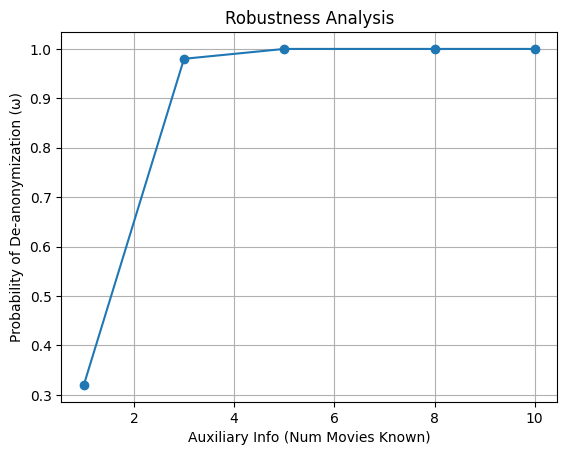

In [ ]:
plt.plot(list(results.keys()), list(results.values()), marker='o')
plt.xlabel("Auxiliary Info (Num Movies Known)")
plt.ylabel("Probability of De-anonymization (ω)")
plt.title("Probability with 1d error")
plt.grid(True)
plt.show()

In [114]:
results = {}
for m_count in [1, 3, 5, 8, 10]:
    w = calculate_deanonymization_probability(
        target_users=test_ids,
        df_nf=df_nf_ratings,
        delta_days=3,
        num_movies_to_keep=m_count,
        weight_map=weight
    )
    results[m_count] = w
    print(f"Con {m_count} film conosciuti, Probabilità (Omega) = {w:.2f}")

Calcolo di Omega su 50 utenti con 1 film noti...
Con 1 film conosciuti, Probabilità (Omega) = 0.32
Calcolo di Omega su 50 utenti con 3 film noti...
Con 3 film conosciuti, Probabilità (Omega) = 0.92
Calcolo di Omega su 50 utenti con 5 film noti...
Con 5 film conosciuti, Probabilità (Omega) = 1.00
Calcolo di Omega su 50 utenti con 8 film noti...
Con 8 film conosciuti, Probabilità (Omega) = 1.00
Calcolo di Omega su 50 utenti con 10 film noti...
Con 10 film conosciuti, Probabilità (Omega) = 0.98


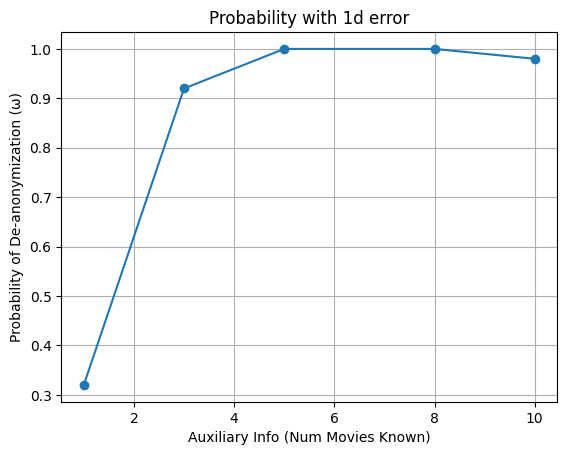

In [ ]:
plt.plot(list(results.keys()), list(results.values()), marker='o')
plt.xlabel("Auxiliary Info (Num Movies Known)")
plt.ylabel("Probability of De-anonymization (ω)")
plt.title("Probability with 3d error")
plt.grid(True)
plt.show()

Calcolo di Omega su 50 utenti con 1 film noti...
Con 1 film conosciuti, Probabilità (Omega) = 0.12
Calcolo di Omega su 50 utenti con 3 film noti...
Con 3 film conosciuti, Probabilità (Omega) = 0.84
Calcolo di Omega su 50 utenti con 5 film noti...
Con 5 film conosciuti, Probabilità (Omega) = 0.98
Calcolo di Omega su 50 utenti con 8 film noti...
Con 8 film conosciuti, Probabilità (Omega) = 0.98
Calcolo di Omega su 50 utenti con 10 film noti...
Con 10 film conosciuti, Probabilità (Omega) = 1.00


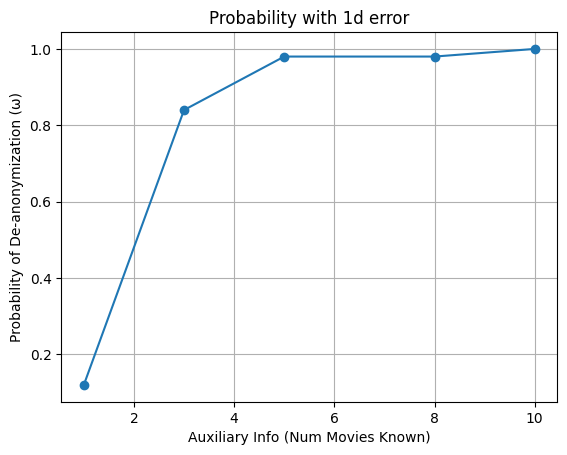

In [ ]:
results = {}
for m_count in [1, 3, 5, 8, 10]:
    w = calculate_deanonymization_probability(
        target_users=test_ids,
        df_nf=df_nf_ratings,
        delta_days=14,
        num_movies_to_keep=m_count,
        weight_map=weight
    )
    results[m_count] = w
    print(f"Con {m_count} film conosciuti, Probabilità (Omega) = {w:.2f}")

plt.plot(list(results.keys()), list(results.values()), marker='o')
plt.xlabel("Auxiliary Info (Num Movies Known)")
plt.ylabel("Probability of De-anonymization (ω)")
plt.title("Probability with 14d error")
plt.grid(True)
plt.show()